# Phase 1 — N-BaIoT Exploratory Analysis and Leakage Audit

**Goal:** Determine up front whether the study's four research questions can be answered.

This notebook trains no detection model. It only answers four questions:

1. **Data integrity** — are there missing/corrupt values or duplicate rows?
2. **Temporal leakage** — how dependent are consecutive rows on each other? Does a random split inflate results?
3. **Device distinguishability** — can devices be told apart from their benign traffic?
4. **Device similarity** — which devices resemble each other?

### Why question 3 is critical

For personalization to yield a gain, devices must be **measurably different** from one another.
If we cannot tell which device a sample belongs to from its benign traffic, a per-device
baseline cannot beat a global baseline.

This is a precondition test. If the answer is negative, we change the framing of the study
from scratch — and that is itself a reportable finding.

### Why question 2 is critical

N-BaIoT features are **sliding-window statistics** computed with five different decay
coefficients (L5, L3, L1, L0.1, L0.01). Consecutive rows share the same packets. The leakage that
50% window overlap creates in HAR studies applies here too.

To measure it, we run the same classification task twice: with a random split and with a
temporal split. The difference is the size of the leakage.

---

**Note:** This notebook does not load TensorFlow. The conflict between `scikit-learn`'s
parallel routines and the CUDA libraries does not occur here.

## 0. Setup

In [1]:
import sys, os, glob, time, json, pickle, warnings
from collections import defaultdict

_PYLIBS = os.path.expanduser("~/work/pylibs")
if os.path.isdir(_PYLIBS) and _PYLIBS not in sys.path:
    sys.path.insert(0, _PYLIBS)

os.environ["OMP_NUM_THREADS"] = "8"

import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt; import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")
matplotlib.rcParams["figure.dpi"] = 60
matplotlib.rcParams["savefig.dpi"] = 300
matplotlib.rcParams["savefig.bbox"] = "tight"

KOK = os.path.expanduser("~/work/IoT_Botnet/veri/nbaiot")
OUT = os.path.expanduser("~/work/IoT_Botnet/faz1_ciktilar")
for s in ("figures", "tables"): os.makedirs(f"{OUT}/{s}", exist_ok=True)

SEED = 42
SALDIRI_ORNEK = 20_000     # samples taken per attack file (to save memory)

def savefig(ad):
    plt.savefig(f"{OUT}/figures/{ad}.png"); plt.show()

print("Data root  :", KOK)
print("Output     :", OUT)
print("pandas", pd.__version__, "| numpy", np.__version__)

Veri koku : /home/jovyan/work/IoT_Botnet/veri/nbaiot
Cikti     : /home/jovyan/work/IoT_Botnet/faz1_ciktilar
pandas 3.0.3 | numpy 2.5.3


## 1. Data loading

Benign traffic is loaded **in full**, attack traffic is loaded **by sampling**. The attack data
has 6.5 million rows and Phase 1 does not need all of it; the full data is needed for
benign profiling and the leakage audit.

Important: the **row order is preserved** within each file. The temporal analysis depends on it.

In [2]:
def dosya_bilgisi(yol):
    """Extract device, family and attack type from the file path."""
    rel = os.path.relpath(yol, KOK)
    p = rel.split(os.sep)
    cihaz = p[0]
    if len(p) == 2:
        return cihaz, "benign", "benign"
    aile = p[1].replace("_attacks", "")
    tur = os.path.splitext(p[-1])[0]
    return cihaz, aile, tur


dosyalar = sorted(glob.glob(f"{KOK}/**/*.csv", recursive=True))
dosyalar = [f for f in dosyalar if "demonstrate" not in f]
print(f"{len(dosyalar)} CSVs found")

t0 = time.time()
parcalar = []
for f in dosyalar:
    cihaz, aile, tur = dosya_bilgisi(f)
    df = pd.read_csv(f, dtype="float32")
    df["satir_no"] = np.arange(len(df), dtype="int32")   # original order within the file
    if aile != "benign" and len(df) > SALDIRI_ORNEK:
        # take from the START, not randomly - preserve temporal order
        df = df.iloc[:SALDIRI_ORNEK].copy()
    df["cihaz"] = cihaz
    df["aile"] = aile
    df["tur"] = tur
    parcalar.append(df)

veri = pd.concat(parcalar, ignore_index=True)
del parcalar
print(f"Loaded: {veri.shape}  ({time.time()-t0:.0f} s, "
      f"{veri.memory_usage(deep=True).sum()/1e9:.2f} GB)")

OZNITELIKLER = [c for c in veri.columns if c not in ("cihaz", "aile", "tur", "satir_no")]
CIHAZLAR = sorted(veri.cihaz.unique())
print(f"\nFeatures: {len(OZNITELIKLER)}  |  Devices: {len(CIHAZLAR)}")
print(veri.groupby(["aile"]).size().to_string())

89 CSV bulundu
Yuklendi: (2155932, 119)  (29 s, 1.14 GB)

Oznitelik: 115  |  Cihaz: 9
aile
benign    555932
gafgyt    900000
mirai     700000


## 2. Data integrity audit

In [3]:
rapor = {}
X = veri[OZNITELIKLER]

rapor["eksik_deger"] = int(X.isna().sum().sum())
rapor["sonsuz_deger"] = int(np.isinf(X.to_numpy()).sum())
rapor["sabit_oznitelik"] = [c for c in OZNITELIKLER if X[c].nunique() <= 1]
rapor["negatif_iceren"] = int((X < 0).any().sum())

print(f"Missing values   : {rapor['eksik_deger']:,}")
print(f"Infinite values  : {rapor['sonsuz_deger']:,}")
print(f"Constant features: {len(rapor['sabit_oznitelik'])} {rapor['sabit_oznitelik'][:5]}")
print(f"With negatives   : {rapor['negatif_iceren']} features")

# Duplicate rows - within device and family
yin = (veri.groupby(["cihaz", "aile"])[OZNITELIKLER]
          .apply(lambda g: g.duplicated().sum()))
rapor["yinelenen_toplam"] = int(yin.sum())
print(f"\nDuplicate rows   : {yin.sum():,} ({100*yin.sum()/len(veri):.2f}%)")
print("\nTop 5 groups with most duplicates:")
print(yin.sort_values(ascending=False).head(5).to_string())

with open(f"{OUT}/tables/f1_butunluk_raporu.json", "w") as fh:
    json.dump({k: (v if not isinstance(v, list) else v) for k, v in rapor.items()},
              fh, indent=2, ensure_ascii=False)

Eksik deger      : 0
Sonsuz deger     : 0
Sabit oznitelik  : 0 []
Negatif iceren   : 20 oznitelik

Yinelenen satir  : 402,043 (18.65%)

En cok yineleme iceren 5 grup:
cihaz                                     aile  
Danmini_Doorbell                          gafgyt    39958
Samsung_SNH_1011_N_Webcam                 gafgyt    39958
SimpleHome_XCS7_1003_WHT_Security_Camera  gafgyt    39957
Ennio_Doorbell                            gafgyt    39956
Ecobee_Thermostat                         gafgyt    39956


## 3. Class imbalance

Most of the data is attack traffic. This is an aggregation artifact caused by attacks producing
many packets; it does not reflect real-world proportions.

**Consequence:** accuracy is meaningless on this dataset. A classifier that says "everything is
an attack" gets high accuracy. Evaluation will be built on F1, MCC and PR-AUC.

                                          benign  gafgyt   mirai  benign_orani_%
cihaz                                                                           
Danmini_Doorbell                           49548  100000  100000           19.86
Ecobee_Thermostat                          13113  100000  100000            6.15
Ennio_Doorbell                             39100  100000       0           28.11
Philips_B120N10_Baby_Monitor              175240  100000  100000           46.70
Provision_PT_737E_Security_Camera          62154  100000  100000           23.71
Provision_PT_838_Security_Camera           98514  100000  100000           33.00
Samsung_SNH_1011_N_Webcam                  52150  100000       0           34.28
SimpleHome_XCS7_1002_WHT_Security_Camera   46585  100000  100000           18.89
SimpleHome_XCS7_1003_WHT_Security_Camera   19528  100000  100000            8.90


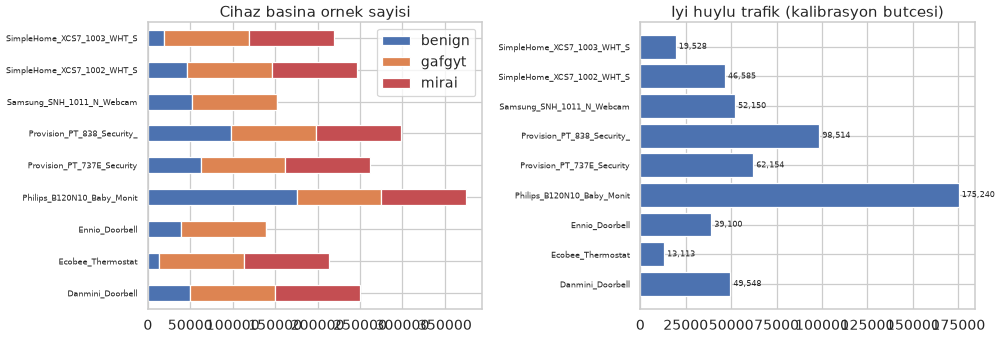


Iyi huylu veride cihazlar arasi oran: 13.4 kat  (en cok Philips_B120N10_Baby, en az Ecobee_Thermostat)


In [4]:
tam_sayim = pd.DataFrame({
    "benign": veri[veri.aile == "benign"].groupby("cihaz").size(),
    "gafgyt": veri[veri.aile == "gafgyt"].groupby("cihaz").size(),
    "mirai":  veri[veri.aile == "mirai"].groupby("cihaz").size(),
}).fillna(0).astype(int).reindex(CIHAZLAR)
tam_sayim["benign_orani_%"] = (100 * tam_sayim.benign /
                               tam_sayim.sum(axis=1)).round(2)
tam_sayim.to_csv(f"{OUT}/tables/f1_tablo1_sinif_dagilimi.csv")
print(tam_sayim.to_string())

fig, ax = plt.subplots(1, 2, figsize=(17, 6))
tam_sayim[["benign", "gafgyt", "mirai"]].plot(
    kind="barh", stacked=True, ax=ax[0], color=["#4c72b0", "#dd8452", "#c44e52"])
ax[0].set_title("Cihaz basina ornek sayisi"); ax[0].set_ylabel("")
ax[0].set_yticklabels([t.get_text()[:26] for t in ax[0].get_yticklabels()], fontsize=9)

b = veri[veri.aile == "benign"].groupby("cihaz").size().reindex(CIHAZLAR)
ax[1].barh(range(len(b)), b.values, color="#4c72b0")
ax[1].set_yticks(range(len(b)))
ax[1].set_yticklabels([c[:26] for c in CIHAZLAR], fontsize=9)
ax[1].set_title("Iyi huylu trafik (kalibrasyon butcesi)")
for i, v in enumerate(b.values):
    ax[1].text(v, i, f" {v:,}", va="center", fontsize=9)
plt.tight_layout(); savefig("f1_fig01_sinif_dagilimi")

print(f"\nRatio across devices in benign data: "
      f"{b.max()/b.min():.1f}x  (most {b.idxmax()[:20]}, least {b.idxmin()[:20]})")

## 4. Feature structure

The 115 features are the product of three dimensions: **flow aggregation type** × **decay coefficient** × **statistic**.
Parsing this structure is needed for the feature-group ablation later.

Akis toplama turleri:
akis
HH        35
HpHp      35
MI_dir    15
H         15
HH_jit    15

Bozunma katsayilari:
bozunma
L5       23
L3       23
L1       23
L0.1     23
L0.01    23

Istatistikler:
istatistik
weight        25
mean          25
variance      15
std           10
magnitude     10
radius        10
covariance    10
pcc           10


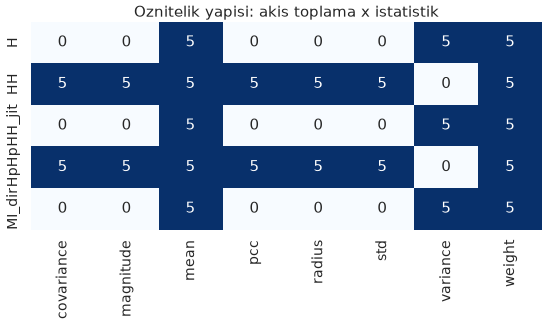

In [5]:
def oznitelik_coz(ad):
    """MI_dir_L5_mean -> (MI_dir, L5, mean)"""
    p = ad.split("_")
    L_idx = [i for i, x in enumerate(p) if x.startswith("L") and
             (x[1:].replace(".", "").isdigit())]
    if not L_idx:
        return ad, "?", "?"
    i = L_idx[0]
    return "_".join(p[:i]), p[i], "_".join(p[i+1:])

coz = pd.DataFrame([oznitelik_coz(c) for c in OZNITELIKLER],
                   columns=["akis", "bozunma", "istatistik"], index=OZNITELIKLER)
coz.to_csv(f"{OUT}/tables/f1_oznitelik_yapisi.csv")

print("Flow aggregation types:")
print(coz.akis.value_counts().to_string())
print("\nDecay coefficients:")
print(coz.bozunma.value_counts().to_string())
print("\nStatistics:")
print(coz.istatistik.value_counts().to_string())

capraz = pd.crosstab(coz.akis, coz.istatistik)
plt.figure(figsize=(11, 4.5))
sns.heatmap(capraz, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Oznitelik yapisi: akis toplama x istatistik")
plt.xlabel(""); plt.ylabel("")
savefig("f1_fig02_oznitelik_yapisi")

## 5. Temporal dependence and leakage audit

This section establishes the methodological foundation of the study.

N-BaIoT features are sliding-window statistics. Consecutive rows share the same packets,
so they are not independent of each other. With a random split, a near-copy of every test row
is found in the training set and performance rises artificially.

We make two measurements:

**5.1** How similarity between consecutive rows decays with lag — beyond what distance can
rows be considered independent?

**5.2** The same classification task with random vs. temporal split — how many points does
the leakage add to performance?

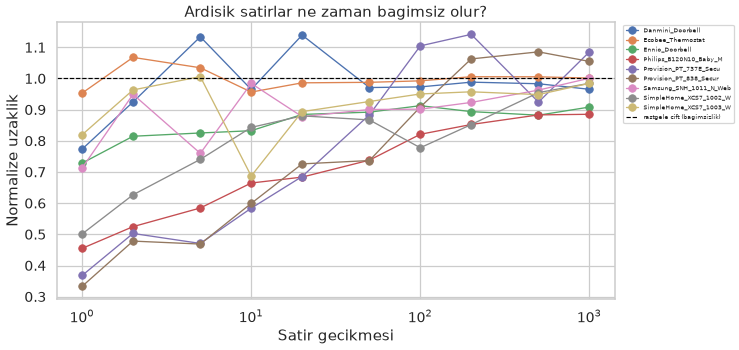

Gecikme 1  -> bagimsizligin %63'i
Gecikme 10 -> bagimsizligin %79'i
Gecikme 100-> bagimsizligin %93'i

1.0'a ne kadar gec yaklasiyorsa, zamansal bagimlilik o kadar uzun surelidir.


In [6]:
# ---- 5.1 Self-similarity by lag ---------------------------------------------
from scipy.spatial.distance import cdist

GECIKMELER = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]
satirlar = []

for cihaz in CIHAZLAR:
    g = veri[(veri.cihaz == cihaz) & (veri.aile == "benign")].sort_values("satir_no")
    A = g[OZNITELIKLER].to_numpy(dtype="float64")
    # scale (features have very different magnitudes)
    A = (A - A.mean(0)) / (A.std(0) + 1e-9)
    n = len(A)
    for lag in GECIKMELER:
        if n <= lag + 10: continue
        m = min(5000, n - lag)
        idx = np.linspace(0, n - lag - 1, m).astype(int)
        d = np.linalg.norm(A[idx] - A[idx + lag], axis=1)
        satirlar.append({"cihaz": cihaz, "gecikme": lag,
                         "ortalama_uzaklik": float(d.mean())})

    # reference: distance between two random rows
    r1 = np.random.RandomState(SEED).choice(n, 5000)
    r2 = np.random.RandomState(SEED + 1).choice(n, 5000)
    d0 = np.linalg.norm(A[r1] - A[r2], axis=1)
    satirlar.append({"cihaz": cihaz, "gecikme": -1,
                     "ortalama_uzaklik": float(d0.mean())})

gec_df = pd.DataFrame(satirlar)
gec_df.to_csv(f"{OUT}/tables/f1_tablo2_gecikme_uzakligi.csv", index=False)

pv = gec_df[gec_df.gecikme > 0].pivot(index="gecikme", columns="cihaz",
                                       values="ortalama_uzaklik")
ref = gec_df[gec_df.gecikme == -1].set_index("cihaz").ortalama_uzaklik

plt.figure(figsize=(12, 6))
for c in CIHAZLAR:
    if c in pv.columns:
        plt.plot(pv.index, pv[c] / ref[c], marker="o", lw=1.6, label=c[:22])
plt.axhline(1.0, color="black", ls="--", lw=1.4, label="rastgele cift (bagimsizlik)")
plt.xscale("log"); plt.xlabel("Satir gecikmesi"); plt.ylabel("Normalize uzaklik")
plt.title("Ardisik satirlar ne zaman bagimsiz olur?")
plt.legend(fontsize=7.5, bbox_to_anchor=(1.01, 1), loc="upper left")
savefig("f1_fig03_zamansal_bagimlilik")

oran10 = (pv.loc[10] / ref[pv.columns]).mean() if 10 in pv.index else np.nan
oran100 = (pv.loc[100] / ref[pv.columns]).mean() if 100 in pv.index else np.nan
print(f"Lag 1   -> {100*(pv.loc[1]/ref[pv.columns]).mean():.0f}% of independence")
print(f"Lag 10  -> {100*oran10:.0f}% of independence")
print(f"Lag 100 -> {100*oran100:.0f}% of independence")
print("\nThe later it approaches 1.0, the longer-lived the temporal dependence.")

In [7]:
# ---- 5.2 Leakage experiment: random vs temporal split -----------------------
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

def bol_ve_egit(bolme, veri_alt, etiket_sutun, n_ornek=40_000):
    """bolme: 'rastgele' | 'zamansal'"""
    rs = np.random.RandomState(SEED)
    tr_idx, te_idx = [], []
    for _, g in veri_alt.groupby(etiket_sutun):
        g = g.sort_values(["cihaz", "satir_no"])
        n = len(g)
        if bolme == "rastgele":
            p = rs.permutation(n); kes = int(0.7 * n)
            tr_idx.append(g.index[p[:kes]]); te_idx.append(g.index[p[kes:]])
        else:
            kes = int(0.7 * n)
            tr_idx.append(g.index[:kes]); te_idx.append(g.index[kes:])
    tr = veri_alt.loc[np.concatenate(tr_idx)]
    te = veri_alt.loc[np.concatenate(te_idx)]
    if len(tr) > n_ornek: tr = tr.sample(n_ornek, random_state=SEED)
    if len(te) > n_ornek: te = te.sample(n_ornek, random_state=SEED)

    sc = StandardScaler().fit(tr[OZNITELIKLER])
    clf = RandomForestClassifier(n_estimators=150, max_depth=25,
                                 random_state=SEED, n_jobs=4)
    clf.fit(sc.transform(tr[OZNITELIKLER]), tr[etiket_sutun])
    p = clf.predict(sc.transform(te[OZNITELIKLER]))
    return (accuracy_score(te[etiket_sutun], p),
            f1_score(te[etiket_sutun], p, average="macro"))

benign = veri[veri.aile == "benign"].copy()

sonuc = []
for bolme in ["rastgele", "zamansal"]:
    t0 = time.time()
    acc, f1 = bol_ve_egit(bolme, benign, "cihaz")
    sonuc.append({"gorev": "cihaz kimligi (iyi huylu)", "bolme": bolme,
                  "accuracy": round(acc, 4), "f1_makro": round(f1, 4),
                  "sure_s": round(time.time() - t0, 1)})
    print(f"  {bolme:<10} acc={acc:.4f}  f1={f1:.4f}  ({time.time()-t0:.0f}s)")

sizinti = pd.DataFrame(sonuc)
fark = sizinti.accuracy.iloc[0] - sizinti.accuracy.iloc[1]
sizinti.to_csv(f"{OUT}/tables/f1_tablo3_sizinti_deneyi.csv", index=False)
print(f"\nLEAKAGE SIZE: {fark:.4f} ({100*fark:.2f} percentage points)")
print("This gap is the artificial performance boost created by the random split.")
print("The TEMPORAL split will be used in the rest of the study.")

  rastgele   acc=0.9807  f1=0.9795  (4s)
  zamansal   acc=0.9768  f1=0.9748  (4s)

SIZINTI BUYUKLUGU: 0.0039 (0.39 yuzde puan)
Bu fark, rastgele bolmenin yarattigi yapay basarim artisidir.
Calismanin geri kalaninda ZAMANSAL bolme kullanilacak.


## 6. Device distinguishability — the precondition for personalization

The temporal-split result of the experiment above is also **our precondition test**.

If devices can be distinguished from their benign traffic with high accuracy, each device has
its own behavioral signature. This is a necessary condition for a per-device baseline to make sense.

Chance level for 9 devices is ≈ 0.111. If temporal-split accuracy is close to that, the
personalization premium is expected to be zero.

Cihaz kimligi dogrulugu (zamansal bolme): 0.9805
Tesaduf duzeyi                          : 0.1111
Tesadufun kac kati                      : 8.8x

Cihaz basina ayirt edilebilirlik (F1):
  0.9997  Philips_B120N10_Baby_Monitor
  0.9981  Danmini_Doorbell
  0.9958  SimpleHome_XCS7_1002_WHT_Security_Camera
  0.9917  Samsung_SNH_1011_N_Webcam
  0.9889  SimpleHome_XCS7_1003_WHT_Security_Camera
  0.9803  Ennio_Doorbell
  0.9693  Ecobee_Thermostat
  0.9530  Provision_PT_838_Security_Camera
  0.9345  Provision_PT_737E_Security_Camera


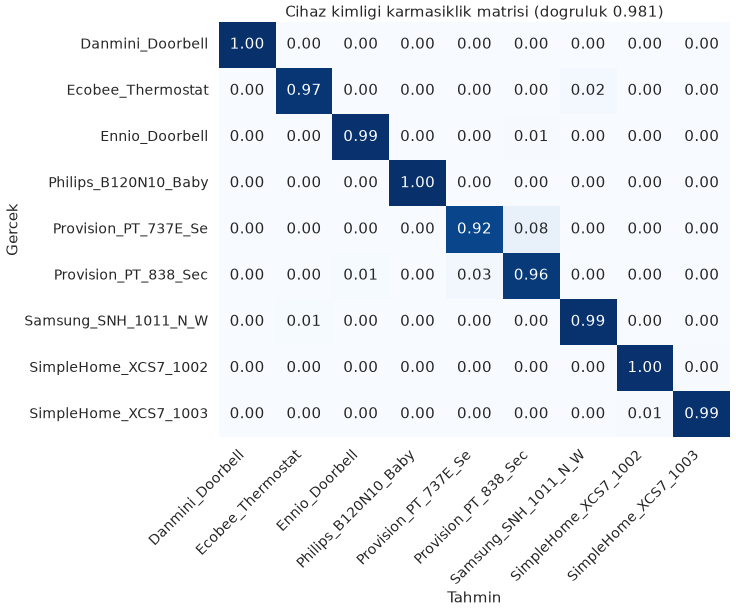

In [8]:
# ---- Per-device distinguishability detail ---------------------------
from sklearn.metrics import confusion_matrix, classification_report

g = benign.sort_values(["cihaz", "satir_no"])
tr_i, te_i = [], []
for _, gg in g.groupby("cihaz"):
    kes = int(0.7 * len(gg))
    tr_i.append(gg.index[:kes]); te_i.append(gg.index[kes:])
tr = g.loc[np.concatenate(tr_i)]; te = g.loc[np.concatenate(te_i)]
if len(tr) > 60_000: tr = tr.sample(60_000, random_state=SEED)

sc = StandardScaler().fit(tr[OZNITELIKLER])
clf = RandomForestClassifier(n_estimators=200, max_depth=25,
                             random_state=SEED, n_jobs=4)
clf.fit(sc.transform(tr[OZNITELIKLER]), tr.cihaz)
pred = clf.predict(sc.transform(te[OZNITELIKLER]))

tesaduf = 1.0 / len(CIHAZLAR)
acc = accuracy_score(te.cihaz, pred)
print(f"Device identity accuracy (temporal split): {acc:.4f}")
print(f"Chance level                           : {tesaduf:.4f}")
print(f"Multiple of chance                    : {acc/tesaduf:.1f}x\n")

rap = classification_report(te.cihaz, pred, zero_division=0, output_dict=True)
cihaz_f1 = pd.Series({k: v["f1-score"] for k, v in rap.items()
                      if k in CIHAZLAR}).sort_values(ascending=False)
cihaz_f1.to_csv(f"{OUT}/tables/f1_tablo4_cihaz_ayirt_edilebilirlik.csv")
print("Per-device distinguishability (F1):")
for k, v in cihaz_f1.items(): print(f"  {v:.4f}  {k}")

cm = confusion_matrix(te.cihaz, pred, labels=CIHAZLAR, normalize="true")
plt.figure(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=[c[:20] for c in CIHAZLAR],
            yticklabels=[c[:20] for c in CIHAZLAR])
plt.title(f"Cihaz kimligi karmasiklik matrisi (dogruluk {acc:.3f})")
plt.xlabel("Tahmin"); plt.ylabel("Gercek")
plt.xticks(rotation=45, ha="right"); plt.yticks(rotation=0)
savefig("f1_fig04_cihaz_ayirt_edilebilirlik")

## 7. Device similarity matrix

The basis of the cross-device transfer analysis (RQ4). We use two measures:

- **Mean profile distance** — distance between devices' standardized mean feature vectors
- **Confusion rate** — how often the classifier above confuses two devices with each other

The second is more meaningful: devices that get confused are devices whose baselines can be transferred to each other.

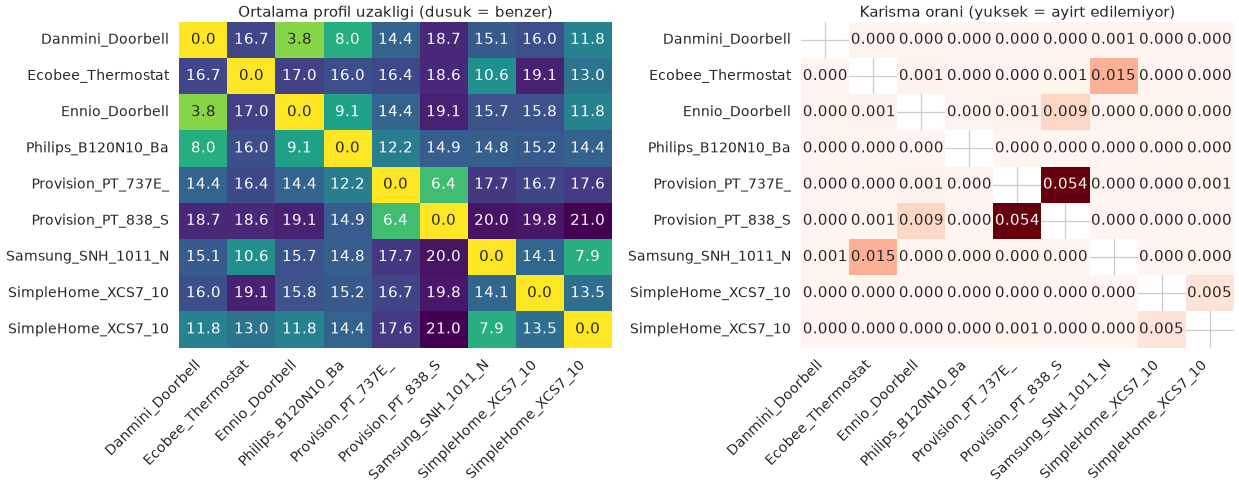

En cok karisan 5 cihaz cifti (aktarim adaylari):
  0.0540  Provision_PT_737E_Security  <->  Provision_PT_838_Security_
  0.0154  Ecobee_Thermostat  <->  Samsung_SNH_1011_N_Webcam
  0.0086  Ennio_Doorbell  <->  Provision_PT_838_Security_
  0.0055  SimpleHome_XCS7_1002_WHT_S  <->  SimpleHome_XCS7_1003_WHT_S
  0.0011  Ennio_Doorbell  <->  Provision_PT_737E_Security

En az karisan 5 cift:
  0.0000  Provision_PT_737E_Security  <->  SimpleHome_XCS7_1002_WHT_S
  0.0000  Ecobee_Thermostat  <->  Philips_B120N10_Baby_Monit
  0.0000  Ecobee_Thermostat  <->  Provision_PT_737E_Security
  0.0000  Ecobee_Thermostat  <->  SimpleHome_XCS7_1002_WHT_S
  0.0000  Philips_B120N10_Baby_Monit  <->  SimpleHome_XCS7_1002_WHT_S


In [9]:
# ---- Mean profile distance -------------------------------------------
prof = benign.groupby("cihaz")[OZNITELIKLER].mean().reindex(CIHAZLAR)
prof_std = (prof - prof.mean()) / (prof.std() + 1e-9)
D = cdist(prof_std.to_numpy(), prof_std.to_numpy(), metric="euclidean")
D_df = pd.DataFrame(D, index=CIHAZLAR, columns=CIHAZLAR)
D_df.to_csv(f"{OUT}/tables/f1_tablo5_profil_uzakligi.csv")

# ---- Confusion rate (symmetric) -------------------------------------------
K = (cm + cm.T) / 2
np.fill_diagonal(K, np.nan)
K_df = pd.DataFrame(K, index=CIHAZLAR, columns=CIHAZLAR)
K_df.to_csv(f"{OUT}/tables/f1_tablo6_karisma_orani.csv")

fig, ax = plt.subplots(1, 2, figsize=(21, 8.5))
sns.heatmap(D_df, annot=True, fmt=".1f", cmap="viridis_r", ax=ax[0], cbar=False,
            xticklabels=[c[:18] for c in CIHAZLAR],
            yticklabels=[c[:18] for c in CIHAZLAR])
ax[0].set_title("Ortalama profil uzakligi (dusuk = benzer)")
sns.heatmap(K_df, annot=True, fmt=".3f", cmap="Reds", ax=ax[1], cbar=False,
            xticklabels=[c[:18] for c in CIHAZLAR],
            yticklabels=[c[:18] for c in CIHAZLAR])
ax[1].set_title("Karisma orani (yuksek = ayirt edilemiyor)")
for a in ax:
    a.tick_params(axis="x", rotation=45); a.tick_params(axis="y", rotation=0)
    for lbl in a.get_xticklabels(): lbl.set_ha("right")
plt.tight_layout(); savefig("f1_fig05_cihaz_benzerligi")

ust = [(CIHAZLAR[i], CIHAZLAR[j], K[i, j])
       for i in range(len(CIHAZLAR)) for j in range(i+1, len(CIHAZLAR))]
ust.sort(key=lambda x: -x[2])
print("Top 5 most-confused device pairs (transfer candidates):")
for a, b, v in ust[:5]: print(f"  {v:.4f}  {a[:26]}  <->  {b[:26]}")
print("\n5 least-confused pairs:")
for a, b, v in ust[-5:]: print(f"  {v:.4f}  {a[:26]}  <->  {b[:26]}")

## 8. Preview of attack separability

In [10]:
# Is there a ceiling effect? How easy is benign vs attack separation?
alt = veri.sample(min(200_000, len(veri)), random_state=SEED).copy()
alt["kotu"] = (alt.aile != "benign").astype(int)

g = alt.sort_values(["cihaz", "aile", "satir_no"])
tr_i, te_i = [], []
for _, gg in g.groupby(["cihaz", "aile"]):
    kes = int(0.7 * len(gg))
    tr_i.append(gg.index[:kes]); te_i.append(gg.index[kes:])
tr = g.loc[np.concatenate(tr_i)]; te = g.loc[np.concatenate(te_i)]

sc = StandardScaler().fit(tr[OZNITELIKLER])
clf = RandomForestClassifier(n_estimators=150, max_depth=20,
                             random_state=SEED, n_jobs=4)
clf.fit(sc.transform(tr[OZNITELIKLER]), tr.kotu)
p = clf.predict(sc.transform(te[OZNITELIKLER]))

from sklearn.metrics import matthews_corrcoef, precision_recall_fscore_support
pr, rc, f1, _ = precision_recall_fscore_support(te.kotu, p, average="binary",
                                                zero_division=0)
print(f"Binary detection (benign vs attack), temporal split:")
print(f"  Accuracy : {accuracy_score(te.kotu, p):.4f}")
print(f"  Precision: {pr:.4f}   Recall: {rc:.4f}   F1: {f1:.4f}")
print(f"  MCC      : {matthews_corrcoef(te.kotu, p):.4f}")
print(f"\nBenign share in test set: {100*(1-te.kotu.mean()):.2f}%")
print("\nIf F1 is above 0.99 there is a CEILING EFFECT: model differences")
print("become invisible on this task. Analyses should shift to harder conditions.")

Ikili tespit (iyi huylu vs saldiri), zamansal bolme:
  Accuracy : 0.9998
  Precision: 0.9999   Recall: 0.9999   F1: 0.9999
  MCC      : 0.9996

Test kumesinde iyi huylu orani: 25.54%

F1 0.99'un uzerindeyse TAVAN ETKISI var demektir: model farklari
bu gorevde gorunmez olur. Analizler zorlastirilmis kosullara kaydirilmalidir.


## 9. Summary and decision

The cell below collects the answers to Phase 1's four questions in one place.

In [11]:
ozet = {
    "veri": {
        "toplam_satir_yuklenen": int(len(veri)),
        "oznitelik": len(OZNITELIKLER),
        "cihaz": len(CIHAZLAR),
        "iyi_huylu_satir": int((veri.aile == "benign").sum()),
    },
    "butunluk": {
        "eksik_deger": rapor["eksik_deger"],
        "sonsuz_deger": rapor["sonsuz_deger"],
        "yinelenen_satir": rapor["yinelenen_toplam"],
        "sabit_oznitelik": len(rapor["sabit_oznitelik"]),
    },
    "sizinti": {
        "rastgele_bolme_dogruluk": float(sizinti.accuracy.iloc[0]),
        "zamansal_bolme_dogruluk": float(sizinti.accuracy.iloc[1]),
        "sizinti_yuzde_puan": round(100 * float(fark), 2),
    },
    "cihaz_ayirt_edilebilirlik": {
        "dogruluk": round(float(acc), 4),
        "tesaduf_duzeyi": round(tesaduf, 4),
        "tesadufun_kati": round(float(acc / tesaduf), 1),
        "en_iyi_cihaz": cihaz_f1.index[0],
        "en_kotu_cihaz": cihaz_f1.index[-1],
    },
}
with open(f"{OUT}/tables/f1_ozet.json", "w") as fh:
    json.dump(ozet, fh, indent=2, ensure_ascii=False)
print(json.dumps(ozet, indent=2, ensure_ascii=False))

print("\n" + "=" * 68)
print("  DECISION POINTS")
print("=" * 68)
k = ozet["cihaz_ayirt_edilebilirlik"]["dogruluk"]
if k > 0.6:
    print(f"  Device distinguishability is HIGH ({k:.3f}).")
    print("  -> The personalization premium is expected to be measurable. RQ1-RQ4 hold.")
elif k > 0.3:
    print(f"  Device distinguishability is MEDIUM ({k:.3f}).")
    print("  -> The premium is measurable but may be small. Device-class-level analysis comes to the fore.")
else:
    print(f"  Device distinguishability is LOW ({k:.3f}).")
    print("  -> The personalization premium is expected to be zero. The framing must be reconsidered.")
s = ozet["sizinti"]["sizinti_yuzde_puan"]
print(f"\n  Leakage size: {s} percentage points.")
print("  -> The TEMPORAL split will be used in all later analyses.")
print("=" * 68)

{
  "veri": {
    "toplam_satir_yuklenen": 2155932,
    "oznitelik": 115,
    "cihaz": 9,
    "iyi_huylu_satir": 555932
  },
  "butunluk": {
    "eksik_deger": 0,
    "sonsuz_deger": 0,
    "yinelenen_satir": 402043,
    "sabit_oznitelik": 0
  },
  "sizinti": {
    "rastgele_bolme_dogruluk": 0.9807,
    "zamansal_bolme_dogruluk": 0.9768,
    "sizinti_yuzde_puan": 0.39
  },
  "cihaz_ayirt_edilebilirlik": {
    "dogruluk": 0.9805,
    "tesaduf_duzeyi": 0.1111,
    "tesadufun_kati": 8.8,
    "en_iyi_cihaz": "Philips_B120N10_Baby_Monitor",
    "en_kotu_cihaz": "Provision_PT_737E_Security_Camera"
  }
}

  KARAR NOKTALARI
  Cihaz ayirt edilebilirligi YUKSEK (0.981).
  -> Kisisellestirme priminin olculebilir olmasi bekleniyor. RQ1-RQ4 gecerli.

  Sizinti buyuklugu: 0.39 yuzde puan.
  -> Tum sonraki analizlerde ZAMANSAL bolme kullanilacak.


In [12]:
import shutil
ars = shutil.make_archive(os.path.expanduser("~/work/IoT_Botnet/faz1_ciktilar"),
                          "zip", OUT)
print("Archive:", ars, f"({os.path.getsize(ars)/1e6:.1f} MB)")
for root, _, fs in os.walk(OUT):
    for f in sorted(fs):
        print("  ", os.path.relpath(os.path.join(root, f), OUT))

Arsiv: /home/jovyan/work/IoT_Botnet/faz1_ciktilar.zip (2.2 MB)
   tables/f1_butunluk_raporu.json
   tables/f1_ozet.json
   tables/f1_oznitelik_yapisi.csv
   tables/f1_tablo1_sinif_dagilimi.csv
   tables/f1_tablo2_gecikme_uzakligi.csv
   tables/f1_tablo3_sizinti_deneyi.csv
   tables/f1_tablo4_cihaz_ayirt_edilebilirlik.csv
   tables/f1_tablo5_profil_uzakligi.csv
   tables/f1_tablo6_karisma_orani.csv
   figures/f1_fig01_sinif_dagilimi.png
   figures/f1_fig02_oznitelik_yapisi.png
   figures/f1_fig03_zamansal_bagimlilik.png
   figures/f1_fig04_cihaz_ayirt_edilebilirlik.png
   figures/f1_fig05_cihaz_benzerligi.png
